--- Loading Cleaned Dataset for EDA ---


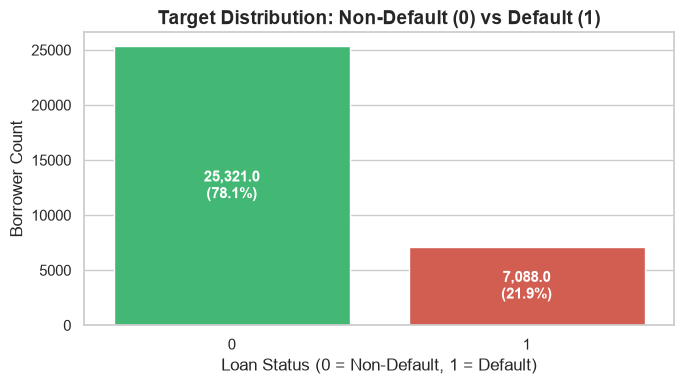

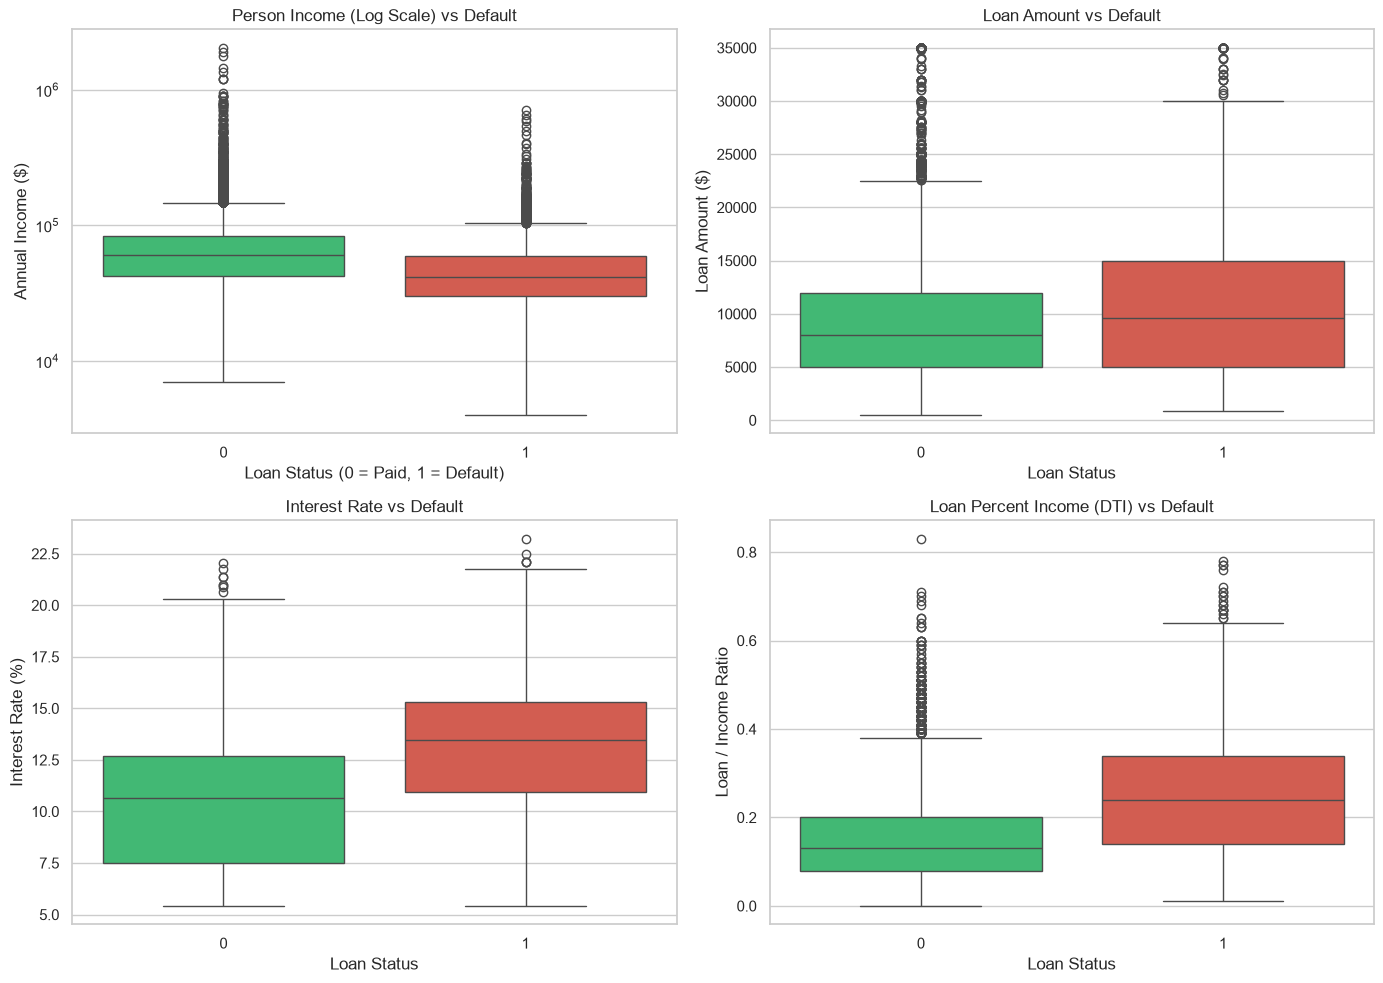

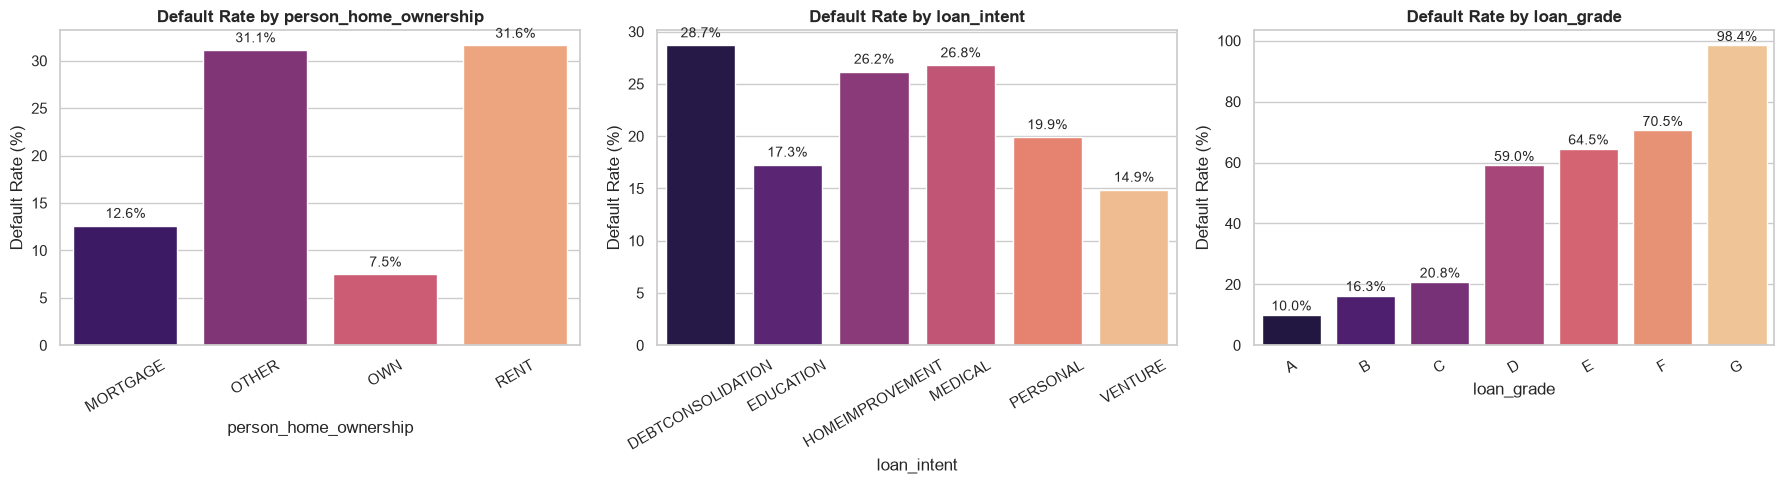

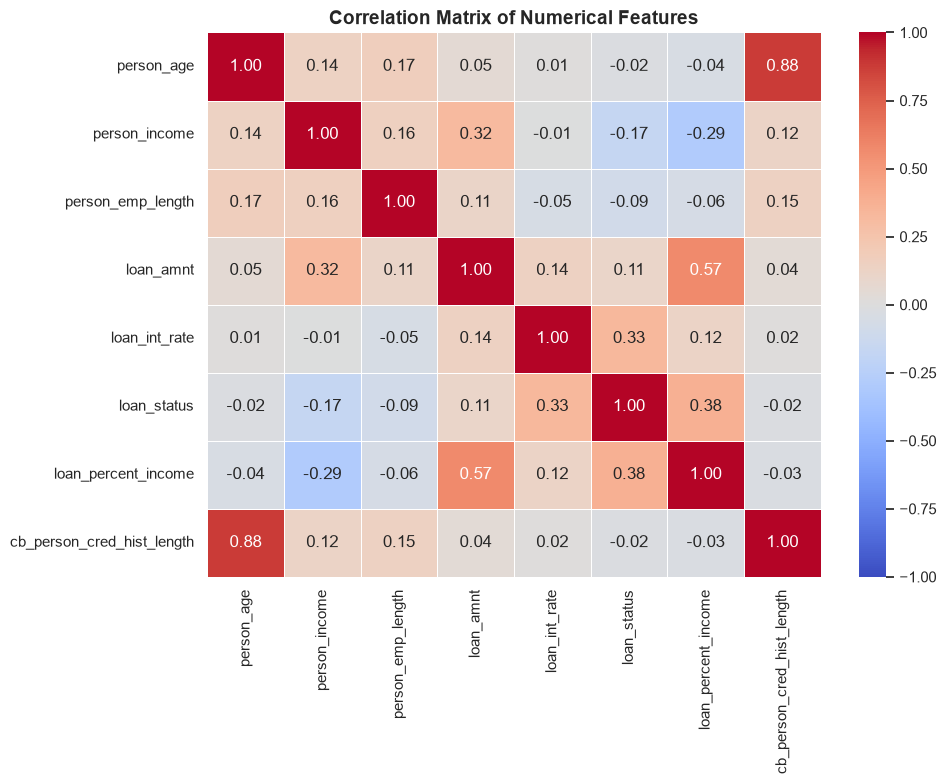

In [4]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style for plots
sns.set_theme(style="whitegrid")
plt.rcParams["font.family"] = "sans-serif"

# Path definition
CLEAN_DATA_PATH = os.path.join("..", "data", "processed", "clean_credit_risk.csv")

def perform_eda(file_path: str):
    if not os.path.exists(file_path):
        file_path = os.path.join("data", "processed", "clean_credit_risk.csv")

    print("--- Loading Cleaned Dataset for EDA ---")
    df = pd.read_csv(file_path)

    # 1. Target Variable Distribution (Class Imbalance Analysis)
    plt.figure(figsize=(7, 4))
    ax = sns.countplot(
        data=df, 
        x='loan_status', 
        hue='loan_status', 
        legend=False, 
        palette=['#2ecc71', '#e74c3c']
    )
    plt.title('Target Distribution: Non-Default (0) vs Default (1)', fontsize=14, fontweight='bold')
    plt.xlabel('Loan Status (0 = Non-Default, 1 = Default)')
    plt.ylabel('Borrower Count')
    
    # Annotate bars with exact percentages
    total = len(df)
    for p in ax.patches:
        height = p.get_height()
        percentage = f"{100 * height / total:.1f}%"
        ax.annotate(f"{height:,}\n({percentage})", (p.get_x() + p.get_width() / 2., height / 2),
                    ha='center', va='center', fontsize=11, color='white', weight='bold')
    plt.tight_layout()
    plt.show()

    # 2. Key Continuous Variable Distributions by Loan Status
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    # Income distribution (log-transformed)
    sns.boxplot(data=df, x='loan_status', y='person_income', hue='loan_status', legend=False, ax=axes[0, 0], palette=['#2ecc71', '#e74c3c'])
    axes[0, 0].set_yscale('log')
    axes[0, 0].set_title('Person Income (Log Scale) vs Default')
    axes[0, 0].set_xlabel('Loan Status (0 = Paid, 1 = Default)')
    axes[0, 0].set_ylabel('Annual Income ($)')

    # Loan Amount vs Default
    sns.boxplot(data=df, x='loan_status', y='loan_amnt', hue='loan_status', legend=False, ax=axes[0, 1], palette=['#2ecc71', '#e74c3c'])
    axes[0, 1].set_title('Loan Amount vs Default')
    axes[0, 1].set_xlabel('Loan Status')
    axes[0, 1].set_ylabel('Loan Amount ($)')

    # Interest Rate vs Default
    sns.boxplot(data=df, x='loan_status', y='loan_int_rate', hue='loan_status', legend=False, ax=axes[1, 0], palette=['#2ecc71', '#e74c3c'])
    axes[1, 0].set_title('Interest Rate vs Default')
    axes[1, 0].set_xlabel('Loan Status')
    axes[1, 0].set_ylabel('Interest Rate (%)')

    # Loan Percent Income vs Default
    sns.boxplot(data=df, x='loan_status', y='loan_percent_income', hue='loan_status', legend=False, ax=axes[1, 1], palette=['#2ecc71', '#e74c3c'])
    axes[1, 1].set_title('Loan Percent Income (DTI) vs Default')
    axes[1, 1].set_xlabel('Loan Status')
    axes[1, 1].set_ylabel('Loan / Income Ratio')

    plt.tight_layout()
    plt.show()

    # 3. Categorical Variables vs Default Rate
    cat_cols = ['person_home_ownership', 'loan_intent', 'loan_grade']
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    for i, col in enumerate(cat_cols):
        default_rates = df.groupby(col)['loan_status'].mean().reset_index()
        default_rates['loan_status'] = default_rates['loan_status'] * 100  # convert to percentage
        
        sns.barplot(
            data=default_rates, 
            x=col, 
            y='loan_status', 
            hue=col, 
            legend=False, 
            ax=axes[i], 
            palette='magma'
        )
        axes[i].set_title(f'Default Rate by {col}', fontsize=12, fontweight='bold')
        axes[i].set_ylabel('Default Rate (%)')
        axes[i].tick_params(axis='x', rotation=30)
        
        for p in axes[i].patches:
            height = p.get_height()
            axes[i].annotate(f"{height:.1f}%", (p.get_x() + p.get_width() / 2., height + 0.5),
                             ha='center', va='bottom', fontsize=10)

    plt.tight_layout()
    plt.show()

    # 4. Correlation Matrix Heatmap
    plt.figure(figsize=(10, 8))
    numeric_df = df.select_dtypes(include=[np.number])
    corr = numeric_df.corr()
    sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
    plt.title('Correlation Matrix of Numerical Features', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    perform_eda(CLEAN_DATA_PATH)